In [66]:
from pathlib import Path
import numpy as np
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
import matplotlib.pyplot as plt
from pystac_client import Client
from rasterio.warp import reproject, Resampling

# (west, south, east, north) in degrees
# AOI = (21.11, 56.185, 21.16, 56.201)

def find_band(folder, band):
    """Find the .tiff file whose name contains e.g. B04"""
    matches = list(Path(folder).glob(f"*{band}*.tiff"))
    assert len(matches) == 1, f"Expected one {band} file in {folder}, found {matches}"
    return matches[0]

def load_whole(path):
    with rasterio.open(path) as src:
        return src.read(1).astype("float32"), src.transform


In [67]:
DATA = Path("../data")

red_25, t_red_25 = load_whole(find_band(DATA / "2025", "B04"))
nir_25, t_nir_25 = load_whole(find_band(DATA / "2025", "B08"))
red_26, t_red_26 = load_whole(find_band(DATA / "2026", "B04"))
nir_26, t_nir_26 = load_whole(find_band(DATA / "2026", "B08"))

print(red_25.shape, nir_25.shape, red_26.shape, nir_26.shape)
print("Grids match:", t_red_25 == t_red_26)
print("Value range 2025 red:", red_25.min(), red_25.max())

(188, 305) (188, 305) (188, 305) (188, 305)
Grids match: True
Value range 2025 red: 0.0043 0.1986


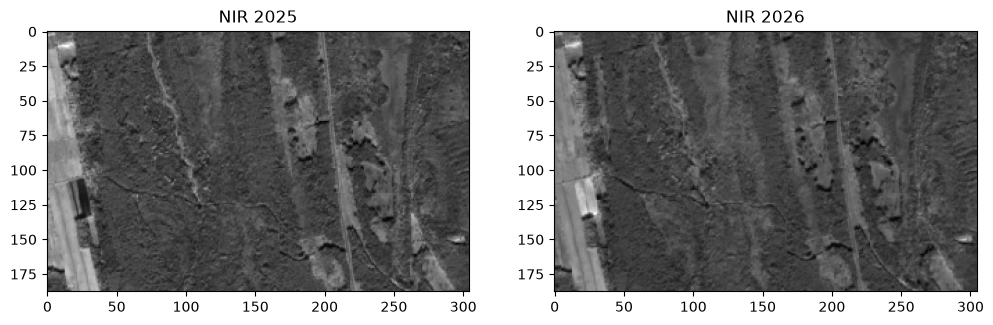

In [68]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(nir_25, cmap='gray')
ax[0].set_title("NIR 2025")

ax[1].imshow(nir_26, cmap="gray")
ax[1].set_title("NIR 2026")

plt.show()

In [69]:
for name, arr in [("red_25", red_25), ("nir_25", nir_25),
                ("red_26", red_26), ("nir_26", nir_26)]:
    print(name, arr.min(), arr.max(), arr.dtype)

red_25 0.0043 0.1986 float32
nir_25 0.039 0.6124 float32
red_26 0.0032 0.1776 float32
nir_26 0.034 0.6245 float32


In [70]:
def ndvi(red, nir):
    return (nir - red) / (nir + red + 1e-6)

ndvi_25 = ndvi(red_25, nir_25)
ndvi_26 = ndvi(red_26, nir_26)

print("2025 NDVI:", ndvi_25.min(), ndvi_25.mean(), ndvi_25.max())
print("2026 NDVI:", ndvi_26.min(), ndvi_26.mean(), ndvi_26.max())

2025 NDVI: 0.15381153 0.8002074 0.92794883
2026 NDVI: 0.1642349 0.8013449 0.9373792


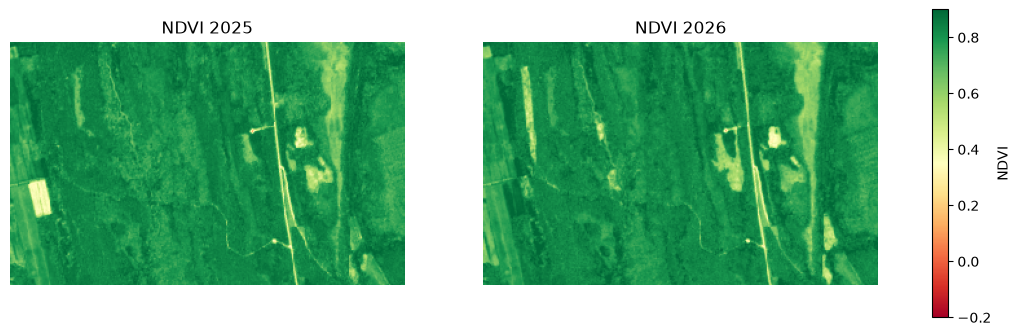

In [71]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for a, data, title in[(ax[0], ndvi_25, "NDVI 2025"),
                      (ax[1], ndvi_26, "NDVI 2026")]:
    im = a.imshow(data, cmap="RdYlGn", vmin=-0.2, vmax=0.9)
    a.set_title(title)
    a.axis("off")

fig.colorbar(im, ax=ax, shrink=0.8, label="NDVI")
plt.show()

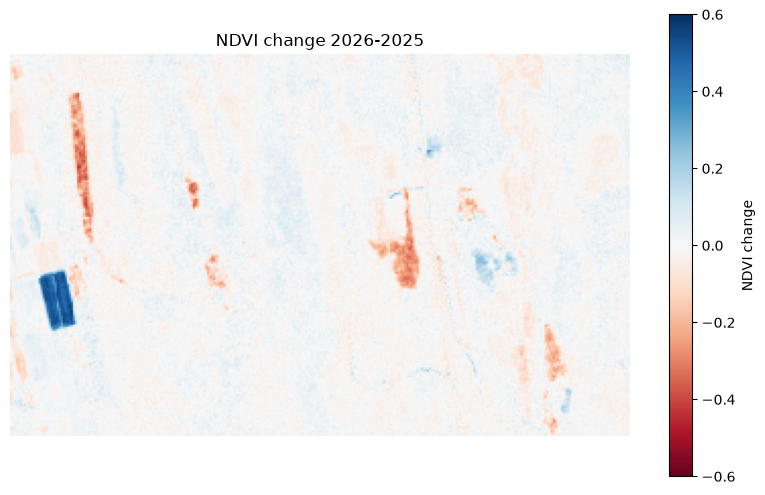

In [72]:
diff = ndvi_26 - ndvi_25

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(diff, cmap="RdBu", vmin=-0.6, vmax=0.6)
ax.set_title("NDVI change 2026-2025")
ax.axis("off")
fig.colorbar(im, ax=ax, label="NDVI change")
plt.show()

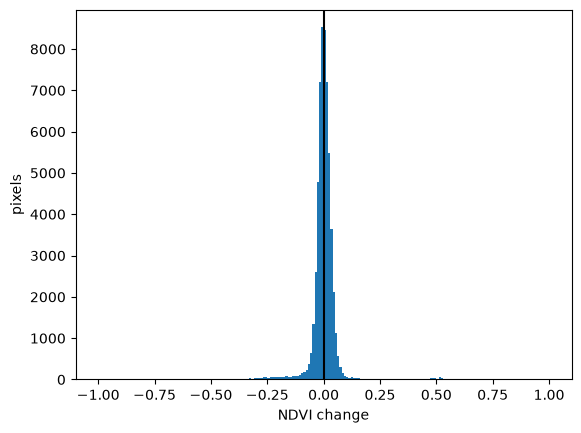

median change: 0.0013802648


In [73]:
plt.hist(diff.ravel(), bins=200, range=(-1, 1))
plt.axvline(0, color="black")
plt.xlabel("NDVI change"); plt.ylabel("pixels")
plt.show()
print("median change:", np.median(diff))